# Exploratory Data Analysis: House Price Dataset

**Task 3 (Codveda Data Science Internship, Level 1)**

**Objective:** compute summary statistics, visualise distributions and relationships, identify correlations, and summarise insights.

**Tools:** Python, pandas, matplotlib, seaborn

**Dataset:** `house_Prediction_DataSet.csv`. It matches the Boston Housing dataset (506 rows, 13 predictors, target `MEDV`).

| Column | Meaning |
|---|---|
| CRIM | Per-capita crime rate |
| ZN | Share of residential land zoned for large lots |
| INDUS | Share of non-retail business acres |
| CHAS | Borders the Charles River (1) or not (0) |
| NOX | Nitric oxide concentration |
| RM | Average rooms per dwelling |
| AGE | Share of owner-occupied units built before 1940 |
| DIS | Distance to employment centres |
| RAD | Highway accessibility index |
| TAX | Property tax rate |
| PTRATIO | Pupil-teacher ratio |
| B | Demographic index (1000(Bk − 0.63)²) |
| LSTAT | % lower-status population |
| MEDV | **Target:** median home value ($1000s) |

## 1. Setup

In [ ]:
import os

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 2. Load the Data
The file is whitespace-separated with no header row, so the separator and column names are set explicitly.

In [ ]:
# loading dataset

cols = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
        "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"]

df = pd.read_csv("house_Prediction_DataSet.csv",
                 sep=r"\s+", header=None, names=cols)

## 3. Dataset Overview

In [ ]:
# inspecting dataset

print(df.shape)
df.info()
df.describe()

**Findings**
- The dataset has **506 rows and 14 columns**, all numeric.
- Every column has 506 non-null values, so there are **no missing values** and no imputation is needed.
- `CHAS` is binary (0/1) and `RAD` is a discrete index (1 to 24). Both behave like categorical variables.
- `MEDV` is the target. Its maximum is exactly 50.0, which suggests the values were capped (see Section 5).

## 4. Summary Statistics
Mean, median, standard deviation, variance, range and skewness for every column.

In [ ]:
# Summary Statistics 

stats = df.describe().T
stats["median"] = df.median()
stats["variance"] = df.var()
stats["skew"] = df.skew()
stats[["mean", "median", "std", "variance", "min", "max", "skew"]]

,mean,median,std,variance,min,max,skew
CRIM,3.613524,0.25651,8.601545,73.986578,0.00632,88.9762,5.223149
ZN,11.363636,0.00000,23.322453,543.936814,0.00000,100.0000,2.225666
INDUS,11.136779,9.69000,6.860353,47.064442,0.46000,27.7400,0.295022
CHAS,0.069170,0.00000,0.253994,0.064513,0.00000,1.0000,3.405904
NOX,0.554695,0.53800,0.115878,0.013428,0.38500,0.8710,0.729308
RM,6.284634,6.20850,0.702617,0.493671,3.56100,8.7800,0.403612
AGE,68.574901,77.50000,28.148861,792.358399,2.90000,100.0000,-0.598963
DIS,3.795043,3.20745,2.105710,4.434015,1.12960,12.1265,1.011781
RAD,9.549407,5.00000,8.707259,75.816366,1.00000,24.0000,1.004815
TAX,408.237154,330.00000,168.537116,28404.759488,187.00000,711.0000,0.669956


**Findings**
- **CRIM** is the most skewed feature (skew ≈ 5.2). The mean (3.61) is far above the median (0.26), so a few extreme areas pull the average up.
- **ZN** is right-skewed (≈ 2.2) with a median of 0. Most areas have no large-lot residential zoning.
- **B** is strongly left-skewed (≈ −2.9). Most values sit near the maximum of about 397.
- **CHAS** has a skew of 3.4, but only because it is binary with about 7% ones.
- **MEDV** (mean 22.5, median 21.2, skew ≈ 1.1) is moderately right-skewed.
- **RM** (mean 6.28, median 6.21, skew ≈ 0.4) is close to symmetric.
- Variance is **not comparable across columns** because the scales differ (TAX variance ≈ 28,000, NOX ≈ 0.013). Skewness and the mean-to-median gap are the fairer comparisons.

## 5. Distributions (Histograms)

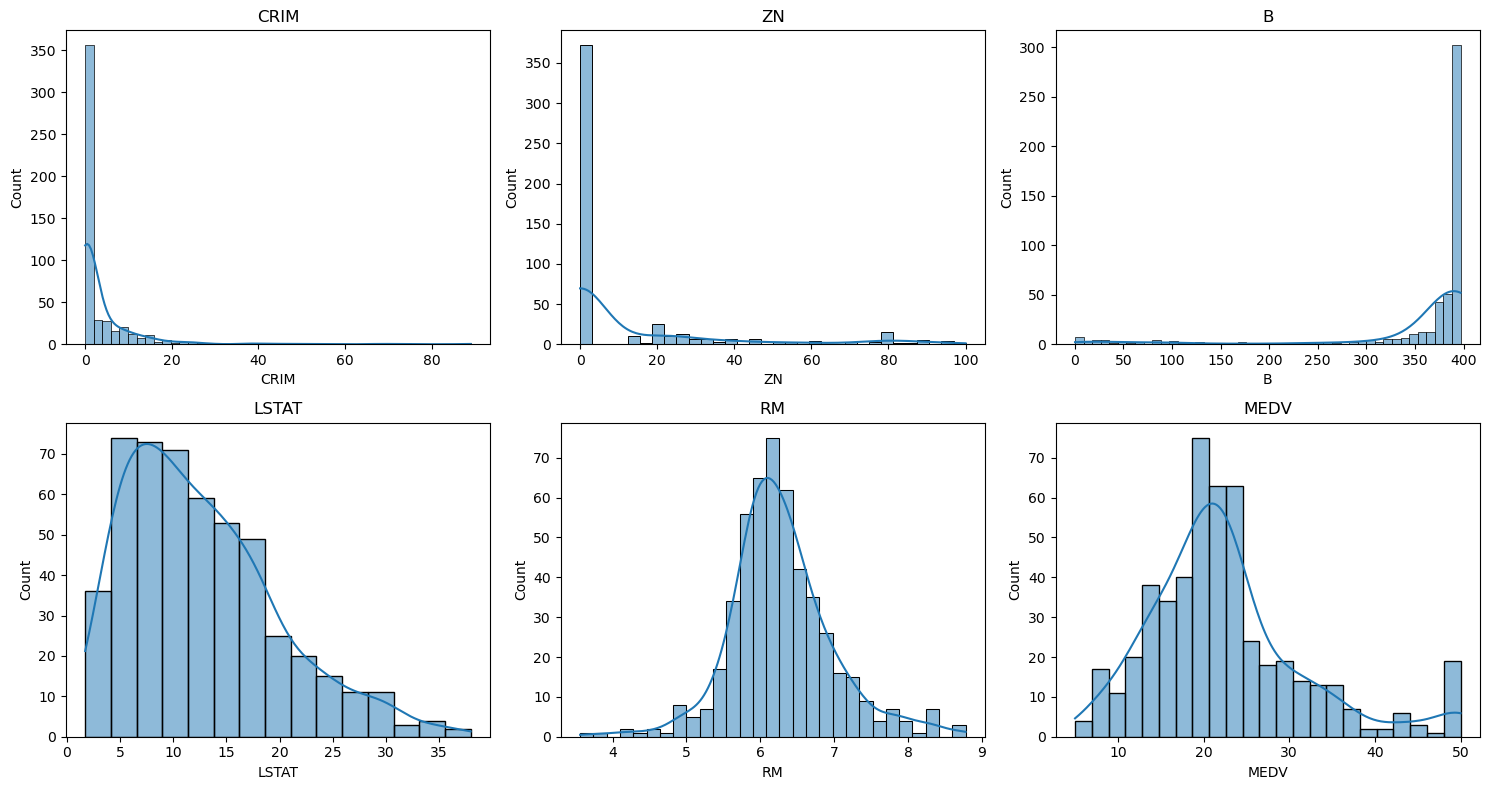

In [ ]:
# Histograms
cols = ["CRIM", "ZN", "B", "LSTAT", "RM", "MEDV"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Findings**
- **CRIM:** most areas have a crime rate near 0, with a long tail out to about 89.
- **ZN:** about 370 areas sit at exactly 0. The rest are spread thinly up to 100.
- **B:** the mirror image of CRIM, with a spike near 400 and a thin tail toward 0.
- **LSTAT:** smooth right skew, with most areas between 5% and 20%.
- **RM:** roughly normal and centred near 6.2 rooms, with a few outliers on both ends.
- **MEDV:** roughly normal around 21, plus a **spike of about 19 houses at 50**. The target is capped at 50, so the true value of those houses is probably higher. This is a data limitation, and any model will underestimate the top end.
- CRIM, ZN and B are clearly non-normal. If these feed a model, a log transform on CRIM would help.

## 6. Relationships with the Target (Scatter Plots)

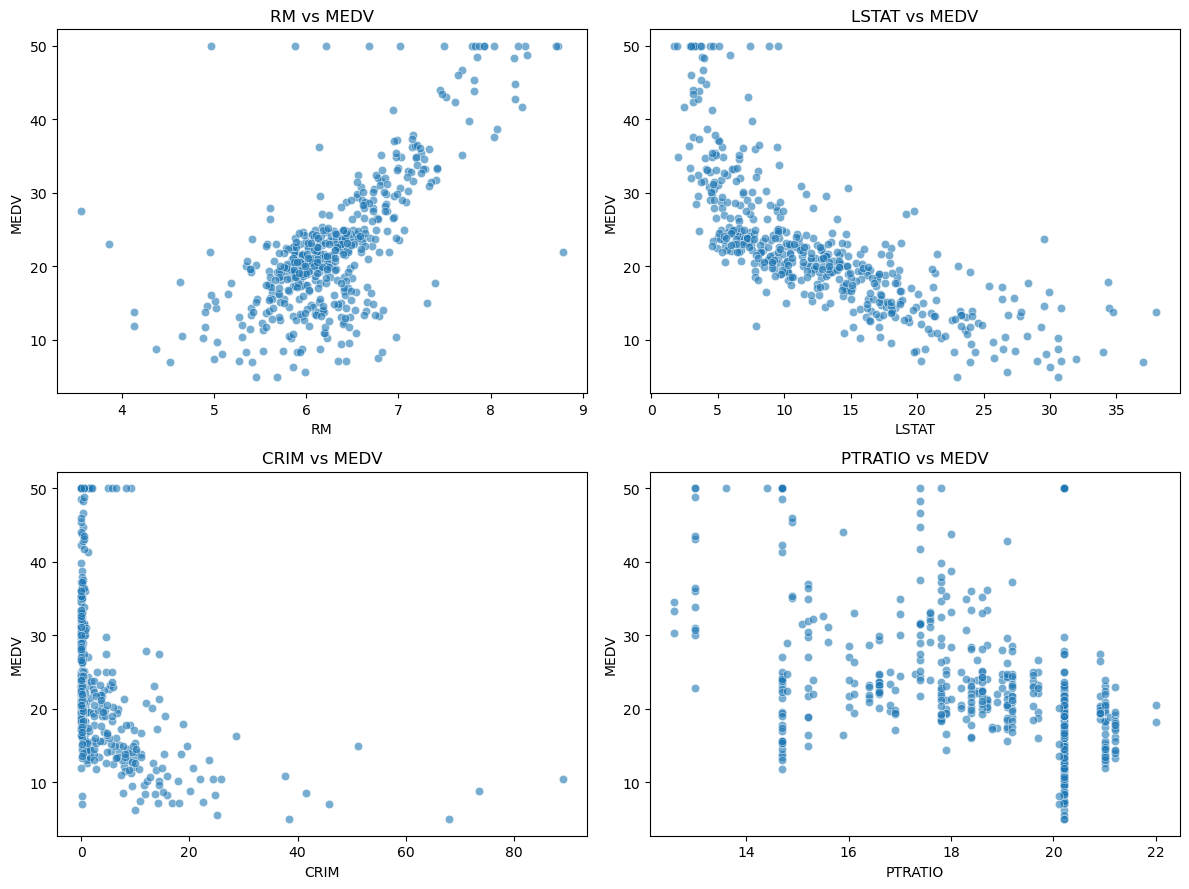

In [ ]:
# Scatter plot 

feats = ["RM", "LSTAT", "CRIM", "PTRATIO"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.ravel(), feats):
    sns.scatterplot(x=df[col], y=df["MEDV"], ax=ax, alpha=0.6)
    ax.set_title(f"{col} vs MEDV")
plt.tight_layout()
plt.show()

**Findings**
- **RM vs MEDV:** clear positive, roughly linear trend. More rooms means a higher price. A few points break the pattern, such as RM below 5 with high prices.
- **LSTAT vs MEDV:** strong negative relationship, but **curved**. Prices fall quickly at low LSTAT, then flatten out. Together with RM, this is the strongest relationship.
- **CRIM vs MEDV:** negative and non-linear. Almost all points sit at CRIM near 0 with prices from 5 to 50, so low crime does not guarantee a high price. High crime does always go with low prices.
- **PTRATIO vs MEDV:** weak negative relationship. PTRATIO takes a limited set of values, which produces vertical stripes and heavy overlap. It is the weakest of the four.
- The flat line at MEDV = 50 appears in every plot and is the cap noted earlier.

## 7. Outliers (Box Plots)

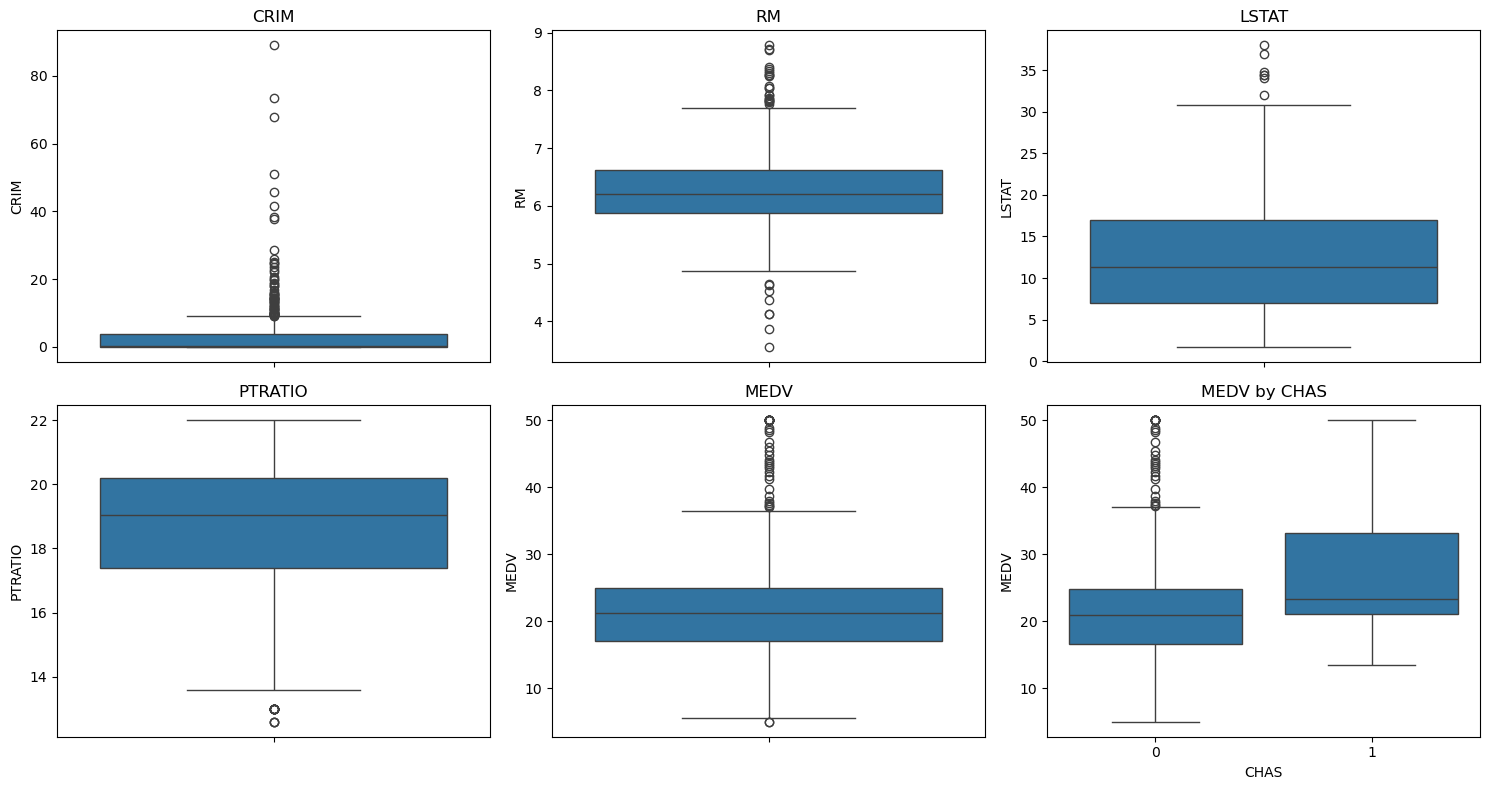

In [ ]:
# Box plots

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["CRIM", "RM", "LSTAT", "PTRATIO", "MEDV"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
sns.boxplot(x="CHAS", y="MEDV", data=df, ax=axes[1, 2])
axes[1, 2].set_title("MEDV by CHAS")
plt.tight_layout()
plt.show()

**Findings**
- **CRIM** has the most outliers by far. The box is squashed near 0 and dozens of points sit above about 9, up to about 89.
- **RM** has outliers on both sides (below about 4.9 and above about 7.7).
- **LSTAT** has a few outliers on the high end only (above about 31).
- **PTRATIO** is the best behaved, with only a couple of low points near 12.6 to 13.
- **MEDV** has outliers only on the high end, and many are the capped 50s. These are a data artefact rather than real extremes.
- **MEDV by CHAS:** houses bordering the Charles River have a higher median (about 23 vs 21) and a higher upper range. Only about 35 houses are in the CHAS = 1 group, so treat this as suggestive rather than conclusive.
- Outliers are **flagged, not removed**, because EDA should describe the data as it is.

## 8. Correlation Analysis
### 8.1 Pearson correlation matrix

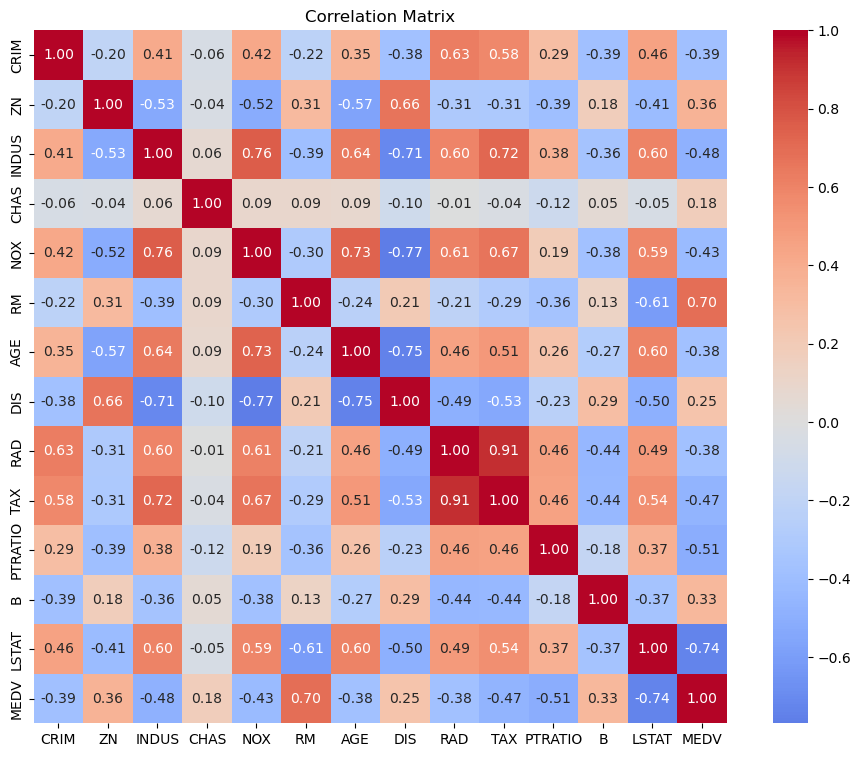

MEDV       1.000000
RM         0.695360
ZN         0.360445
B          0.333461
DIS        0.249929
CHAS       0.175260
AGE       -0.376955
RAD       -0.381626
CRIM      -0.388305
NOX       -0.427321
TAX       -0.468536
INDUS     -0.483725
PTRATIO   -0.507787
LSTAT     -0.737663
Name: MEDV, dtype: float64

In [ ]:
# Correlation matrix

corr = df.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Matrix")
plt.show()

corr["MEDV"].sort_values(ascending=False)

**Findings: correlation with MEDV**
- **Strongest positive:** RM (0.70), then ZN (0.36) and B (0.33).
- **Strongest negative:** LSTAT (−0.74), then PTRATIO (−0.51), INDUS (−0.48) and TAX (−0.47).
- **CHAS** is weakly related (0.18), consistent with the small-group finding in Section 7.

**Findings: multicollinearity (feature pairs with |r| above about 0.7)**
- **RAD and TAX: 0.91.** This is the strongest pair, and the two carry nearly the same information.
- NOX and DIS (−0.77), INDUS and NOX (0.76), AGE and DIS (−0.75), AGE and NOX (0.73), INDUS and TAX (0.72), INDUS and DIS (−0.71).
- INDUS, NOX, AGE, DIS, TAX and RAD form one cluster. This fits the picture of older industrial areas with more pollution, close to employment centres.
- In a linear regression this cluster would inflate coefficient variance. Drop or combine some of these features (for example keep TAX and drop RAD).

### 8.2 Spearman check
Pearson only measures linear association. Spearman captures any monotonic relationship, which matters for the curved LSTAT pattern.

In [ ]:
# Spearman check (captures non-linear monotonic relationships)

df.corr(method="spearman")["MEDV"].sort_values()

LSTAT     -0.852914
INDUS     -0.578255
NOX       -0.562609
TAX       -0.562411
CRIM      -0.558891
PTRATIO   -0.555905
AGE       -0.547562
RAD       -0.346776
CHAS       0.140612
B          0.185664
ZN         0.438179
DIS        0.445857
RM         0.633576
MEDV       1.000000
Name: MEDV, dtype: float64

**Findings: Pearson vs Spearman**
- **LSTAT** rises from −0.74 (Pearson) to **−0.85** (Spearman). This confirms the curved relationship seen in the scatter plot: LSTAT is the strongest single predictor of price, and Pearson understates it.
- **CRIM** rises from −0.39 to **−0.56**. Its link with price is consistently negative but non-linear, and its extreme outliers weaken Pearson.
- **RM** falls from 0.70 to 0.63. Its outliers inflate the linear correlation a little, but it remains the strongest positive predictor.
- **NOX** (−0.43 to −0.56), **AGE** (−0.38 to −0.55), **DIS** (0.25 to 0.45) and **ZN** (0.36 to 0.44) are all stronger under Spearman, so their relationships are monotonic but not linear.
- **RAD** (−0.38 to −0.35) and **CHAS** (0.18 to 0.14) barely change, and both stay weak.
- The ranking of the top predictors (LSTAT, RM, then INDUS, NOX, TAX, CRIM, PTRATIO) is the same under both methods, so the main conclusions are robust.

## 9. Key Insights and Conclusions

1. **Data quality is good.** 506 complete rows, no missing values, all numeric.
2. **Two features drive price most:** RM (positive, r = 0.70) and LSTAT (negative, r = −0.74, Spearman −0.85). Larger homes in higher-status areas are worth more.
3. **LSTAT is non-linear.** A linear model would miss part of its effect, so a transformation or a non-linear model is worth trying.
4. **Several features are heavily skewed** (CRIM, ZN, B). CRIM in particular has extreme outliers and would benefit from a log transform.
5. **The target is capped at 50.** About 19 houses are truncated, so predictions at the top end will be biased low.
6. **Multicollinearity exists.** The INDUS, NOX, AGE, DIS, TAX and RAD cluster, led by RAD and TAX (0.91), should be reduced before linear modelling.
7. **Riverside effect is suggestive only.** CHAS = 1 houses are priced higher, but the group is small.

**Limitations:** correlation does not imply causation, the dataset is a historical snapshot of one metropolitan area, and the `B` column is built from a demographic formula that raises ethical concerns, so treat it with caution in any real application.

**Next step:** build a baseline regression using RM, LSTAT, PTRATIO and one of TAX or RAD, and evaluate it with R² and RMSE.